In [125]:
# Midterm
#imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags_array
from scipy.sparse.linalg import spsolve

#physical parameters
mu = 1e-3 # viscosity Pa·s
g = 9.81 # gravitation acceleration rate m/s²
phi = 0.3 # porosity
rho = 1000 # density kg/m³

#grid
Lx = 100.0 # m
Ly = 50.0 # m
nx = 100
ny = 50
nc = nx * ny
dx = Lx / nx
dy = Ly / ny

xCells = np.arange(dx / 2, Lx, dx)
yCells = np.arange(dy / 2, Ly, dy)
xx, yy = np.meshgrid(xCells, yCells)

#boundary conditions
uin = 0.1 / 100 / 60   # [m/s]  neumann left boundary
hR  = 9.0              # [m]    dirichlet right boundary

In [126]:

#load permeability field
permeability_field = r"/Users/agneskoury/Downloads/permeability_field.csv"

kmat_raw = np.loadtxt(permeability_field, delimiter=',')
logk_original = np.log10(kmat_raw)

mean_logk = -10 # mean of log10(k) k=-10
std_logk  = 1 # standard deviation of log10(k) k=1

Y = (logk_original - mean_logk) / std_logk

sigmas = [0.1, 0.5, 1.0, 2.0] #heterogeneity levels

# time points
tPlot_days = np.array([5, 10, 15, 20, 25, 30])
tPlot      = tPlot_days * 24 * 3600

n_particles = 20000 # number of particles
norm_count  = 2000.0   # average particles per 1m in the initial plume

# storage
pt_xFixed = {}
pt_yFixed = {}
pt_arrivalTime = {}
head_results = {}
K_results = {}
time_results = {}
outlet_flux_fvm = {}
fvm_results = {}

In [127]:
#transmissibility and matrix
def solve_flow(Kmat):

    K_har_x = (
        2.0 / (1.0 / Kmat[:, :nx-1] + 1.0 / Kmat[:, 1:nx])
    )
    K_har_y = (
        2.0 / (1.0 / Kmat[:ny-1, :] + 1.0 / Kmat[1:ny, :])
    )

    TLmat = np.full((ny, nx), np.nan)
    TLmat[:, 0]     = 0.0
    TLmat[:, 1:nx]  = (2.0 / dx) * dy * K_har_x

    TRmat = np.full((ny, nx), np.nan)
    TRmat[:, nx-1]  = (2.0 / dx) * dy * Kmat[:, nx-1]
    TRmat[:, :nx-1] = (2.0 / dx) * dy * K_har_x

    TUmat = np.full((ny, nx), np.nan)
    TUmat[0, :]     = 0.0
    TUmat[1:ny, :]  = (2.0 / dy) * dx * K_har_y

    TDmat = np.full((ny, nx), np.nan)
    TDmat[ny-1, :]  = 0.0
    TDmat[:ny-1, :] = (2.0 / dy) * dx * K_har_y

    TL = TLmat.flatten(order='F')
    TR = TRmat.flatten(order='F')
    TU = TUmat.flatten(order='F')
    TD = TDmat.flatten(order='F')
    TC = TL + TR + TU + TD

    Tmat = (
        diags_array(TC,             offsets=0,   shape=(nc, nc))
        + diags_array(-TL[ny:nc],   offsets=-ny, shape=(nc, nc))
        + diags_array(-TU[1:nc],    offsets=-1,  shape=(nc, nc))
        + diags_array(-TD[0:nc-1],  offsets=1,   shape=(nc, nc))
        + diags_array(-TR[0:nc-ny], offsets=ny,  shape=(nc, nc))
    ).tocsc()

    bmat          = np.zeros((ny, nx))
    bmat[:, 0]    = uin * dy
    bmat[:, nx-1] = TRmat[:, nx-1] * hR
    b             = bmat.flatten(order='F')

    h    = spsolve(Tmat, b)
    hmat = h.reshape((ny, nx), order='F')

    # TLmat and TRmat no longer needed outside — only return what is used
    return hmat, K_har_x, K_har_y

In [128]:
# face Darcy velocities
def compute_velocities(Kmat, hmat, K_har_x, K_har_y):

    # head differences across cell faces
    dh_x = hmat[:, :nx-1] - hmat[:, 1:nx]
    dh_y = hmat[:ny-1, :] - hmat[1:ny, :]

    UL = np.full((ny, nx), np.nan)
    UL[:, 0]    = uin
    UL[:, 1:nx] = (2.0 / dx) * dy * K_har_x / dy * dh_x

    UR = np.full((ny, nx), np.nan)
    UR[:, nx-1]  = (2.0 / dx) * dy * Kmat[:, nx-1] / dy * (hmat[:, nx-1] - hR)
    UR[:, :nx-1] = (2.0 / dx) * dy * K_har_x / dy * dh_x

    UU = np.full((ny, nx), np.nan)
    UU[0, :]    = 0.0
    UU[1:ny, :] = -K_har_y * (hmat[1:ny, :] - hmat[:ny-1, :]) / dy

    UD = np.full((ny, nx), np.nan)
    UD[ny-1, :] = 0.0
    UD[:ny-1, :] = UU[1:ny, :]

    # Cell-centered velocities
    Ux = 0.5 * (UL + UR)
    Uy = 0.5 * (UU + UD)

    # Magnitude of cell-centered velocity
    V_mag = np.sqrt(Ux**2 + Uy**2) / phi
    V_max = np.max(V_mag)

    return UL, UR, UU, UD, Ux, Uy, V_mag, V_max

def fvm_step(Cmat, UL, UR, UU, UD):

    C_in = 0.0

    CL = np.full((ny, nx), np.nan)
    CR = np.full((ny, nx), np.nan)
    CU = np.full((ny, nx), np.nan)
    CD = np.full((ny, nx), np.nan)

    CL[:, 0]     = C_in
    CL[:, 1:nx]  = Cmat[:, :nx-1]

    CR[:, nx-1]  = Cmat[:, nx-1]
    CR[:, :nx-1] = Cmat[:, 1:nx]

    CU[0, :]     = 0.0
    CU[1:ny, :]  = Cmat[:ny-1, :]

    CD[ny-1, :]  = 0.0
    CD[:ny-1, :] = Cmat[1:ny, :]

    # advection flux
    Fadv_L = np.full((ny, nx), np.nan)
    Fadv_R = np.full((ny, nx), np.nan)
    Fadv_U = np.full((ny, nx), np.nan)
    Fadv_D = np.full((ny, nx), np.nan)

    # upwinding
    ind = UL >= 0
    Fadv_L[ind]  = UL[ind]  * CL[ind]
    Fadv_L[~ind] = UL[~ind] * Cmat[~ind]

    ind = UR >= 0
    Fadv_R[ind]  = UR[ind]  * Cmat[ind]
    Fadv_R[~ind] = UR[~ind] * CR[~ind]

    ind = UU >= 0
    Fadv_U[ind]  = UU[ind]  * CU[ind]
    Fadv_U[~ind] = UU[~ind] * Cmat[~ind]

    ind = UD >= 0
    Fadv_D[ind]  = UD[ind]  * Cmat[ind]
    Fadv_D[~ind] = UD[~ind] * CD[~ind]

    netFadv = (
        -Fadv_L * dy
        - Fadv_U * dx
        + Fadv_D * dx
        + Fadv_R * dy
    )

    outlet_flux = np.sum(Fadv_R[:, nx-1] * dy)

    return netFadv, outlet_flux

In [129]:
# heterogeneity levels loop

for sigma in sigmas:

    # permeability
    logk_new = mean_logk + sigma * Y
    k_new    = 10.0 ** logk_new
    Kmat     = rho * g / mu * k_new
    K_results[sigma] = Kmat.copy()

    # steady-state flow
    hmat, K_har_x, K_har_y = solve_flow(Kmat)

    UL, UR, UU, UD, Ux, Uy, V_mag, V_max = compute_velocities(
    Kmat, hmat, K_har_x, K_har_y
    )

    # pore velocities on faces (for pollock)
    vL = UL / phi
    vR = UR / phi
    vU = UU / phi
    vD = UD / phi

    Cmat   = np.where(xx <= 10.0, 1.0, 0.0)
    t      = 0.0
    itPlot = 0

    saved_C_fvm = {}
    fvm_times   = []
    fvm_fluxes  = []

    M0_fvm  = np.sum(Cmat) * phi * dx * dy
    ext_end = 200 * 24 * 3600

    while t < ext_end:

        netFadv, outlet_flux = fvm_step(Cmat, UL, UR, UU, UD)

        dt = 0.1 * dx / V_max

        if itPlot < len(tPlot) and tPlot[itPlot] > t:
            dt = min(dt, tPlot[itPlot] - t)

        dt = min(dt, ext_end - t)

        t += dt
        Cmat  = Cmat - dt / (phi * dx * dy) * netFadv

        fvm_times.append(t)
        fvm_fluxes.append(outlet_flux)

        # snapshots at plot timess
        if itPlot < len(tPlot) and t >= tPlot[itPlot] - 1e-10:
            day = t / (24 * 3600)
            saved_C_fvm[day] = Cmat.copy()
            itPlot += 1
        
        M_rem = np.sum(np.maximum(Cmat, 0.0)) * phi * dx * dy
        if t > 30 * 24 * 3600 and M_rem < 1e-3 * M0_fvm:
            break
        
    fvm_results[sigma] = saved_C_fvm
    outlet_flux_fvm[sigma] = (np.array(fvm_times), np.array(fvm_fluxes))

    # particle tracking pollock's method
    np_pt = n_particles # number of particles

    # initial positions
    rng = np.random.default_rng(seed=42)
    x0  = rng.uniform(0.0, 10.0, np_pt)
    y0  = rng.uniform(0.0, Ly,   np_pt)

    # track arrays
    max_step = 200 * nx 
    xTrack   = np.full((np_pt, max_step), np.nan)
    yTrack   = np.full((np_pt, max_step), np.nan)
    tTrack   = np.full((np_pt, max_step), np.nan)

    xTrack[:, 0] = x0
    yTrack[:, 0] = y0
    tTrack[:, 0] = 0.0

    active = np.ones(np_pt, dtype=bool) # whether still inside model domain
    step   = 0 # iteration step

    while np.any(active):

        step += 1

        ip_active = np.where(active)[0]
        # next location
        xp = xTrack[ip_active, step - 1]
        yp = yTrack[ip_active, step - 1]
        tp = tTrack[ip_active, step - 1]

        # index of cells containing particles
        ix = np.clip(np.floor(xp / dx).astype(int), 0, nx - 1)   # col
        iy = np.clip(np.floor(yp / dy).astype(int), 0, ny - 1)   # row

        # pore velocities face
        _vL = vL[iy, ix]
        _vR = vR[iy, ix]
        _vU = vU[iy, ix]
        _vD = vD[iy, ix]

        # cell-face coordinates
        xL = ix * dx
        xR = (ix + 1) * dx
        yT = iy * dy
        yB  = (iy + 1) * dy

        # velocity gradients
        Ax = (_vR - _vL) / dx
        Ay = (_vD - _vU) / dy

        # velocity at particle locations
        vxp = _vL + Ax * (xp - xL)
        vyp = _vU + Ay * (yp - yT)

        #exit velocities
        vxExit = np.where(vxp >= 0, _vR, _vL)
        vyExit = np.where(vyp >= 0, _vD, _vU)

        # exit times
        with np.errstate(divide='ignore', invalid='ignore'):
            tauX = np.where(
                np.abs(Ax) > 1e-30,
                np.log(np.abs(vxExit / np.where(np.abs(vxp) > 1e-30, vxp, 1e-30))) / Ax,
                np.where(np.abs(vxp) > 1e-30,
                         np.where(vxp > 0,
                                  (xR - xp) / vxp,
                                  (xL - xp) / vxp),
                         np.inf)
            )
            tauY = np.where(
                np.abs(Ay) > 1e-30,
                np.log(np.abs(vyExit / np.where(np.abs(vyp) > 1e-30, vyp, 1e-30))) / Ay,
                np.where(np.abs(vyp) > 1e-30,
                         np.where(vyp > 0,
                                  (yB - yp) / vyp,
                                  (yT - yp) / vyp),
                         np.inf)
            )

        tauX = np.where(tauX > 0, tauX, np.inf)
        tauY = np.where(tauY > 0, tauY, np.inf)
        tau  = np.minimum(tauX, tauY)

        # move particles
        with np.errstate(divide='ignore', invalid='ignore'):
            xp_new = np.where(
                np.abs(Ax) > 1e-30,
                xL + (vxp * np.exp(Ax * tau) - _vL) / Ax,
                xp + vxp * tau
            )
            yp_new = np.where(
                np.abs(Ay) > 1e-30,
                yT  + (vyp * np.exp(Ay * tau) - _vU) / Ay,
                yp + vyp * tau
            )

        tp_new = tp + tau

        # infinitesimally move particle into next cell
        xp_new = np.where(vxp >= 0,
                          xp_new + 1e-10 * dx,
                          xp_new - 1e-10 * dx)
        yp_new = np.where(vyp >= 0,
                          yp_new + 1e-10 * dy,
                          yp_new - 1e-10 * dy)

        # save
        xTrack[ip_active, step] = xp_new
        yTrack[ip_active, step] = yp_new
        tTrack[ip_active, step] = tp_new

        # check if particles have reached the outlet
        exited = xTrack[ip_active, step] > Lx - 1e-10 * dx
        active[ip_active[exited]] = False

        # deactivate stagnant particles
        stagnant = ~np.isfinite(tau)
        active[ip_active[stagnant]] = False

    tFixed   = np.arange(1, 200 + 1) * 24 * 3600
    n_tFixed = len(tFixed)

    xFixed_arr  = np.full((np_pt, n_tFixed), np.nan)
    yFixed_arr  = np.full((np_pt, n_tFixed), np.nan)
    arrivalTime = np.full(np_pt, np.nan)

    for p in range(np_pt):
        tp_full = tTrack[p, :]
        valid   = np.isfinite(tp_full)
        if not np.any(valid):
            continue

        tp_v = tp_full[valid]
        xp_v = xTrack[p, valid]
        yp_v = yTrack[p, valid]

        # remove duplicate times
        _, ia   = np.unique(tp_v, return_index=True)
        tp_v    = tp_v[ia]
        xp_v    = xp_v[ia]
        yp_v    = yp_v[ia]

        arrivalTime[p] = tp_v[-1]

        mask = (tFixed >= tp_v[0]) & (tFixed <= tp_v[-1])
        if np.any(mask):
            xFixed_arr[p, mask] = np.interp(tFixed[mask], tp_v, xp_v)
            yFixed_arr[p, mask] = np.interp(tFixed[mask], tp_v, yp_v)

    pt_xFixed[sigma]      = xFixed_arr
    pt_yFixed[sigma]      = yFixed_arr
    pt_arrivalTime[sigma] = arrivalTime
    time_results[sigma]   = tPlot_days.astype(float)


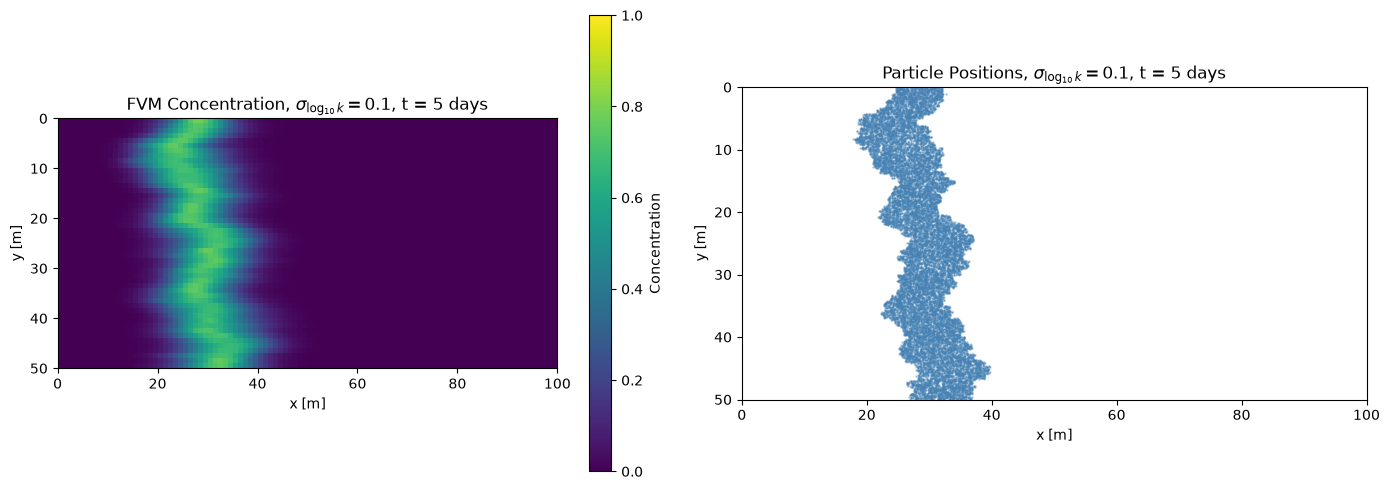

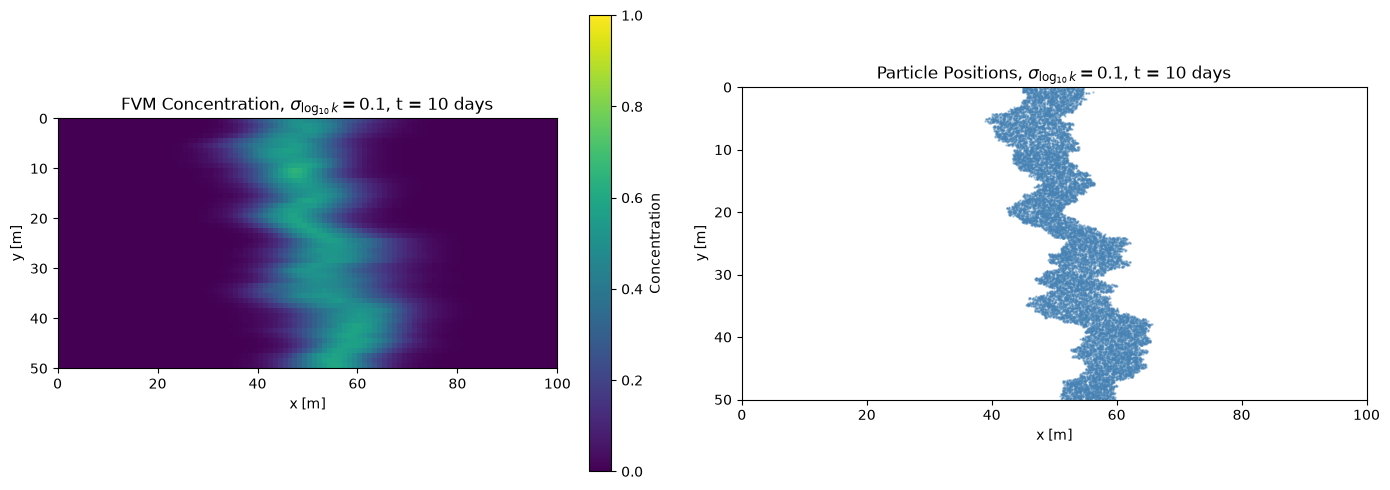

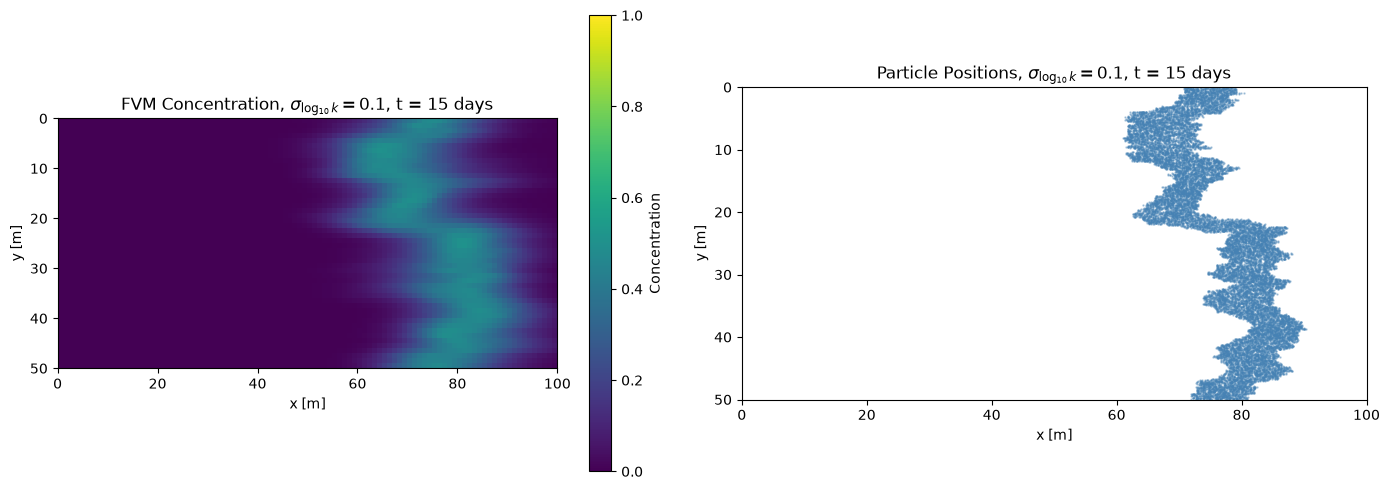

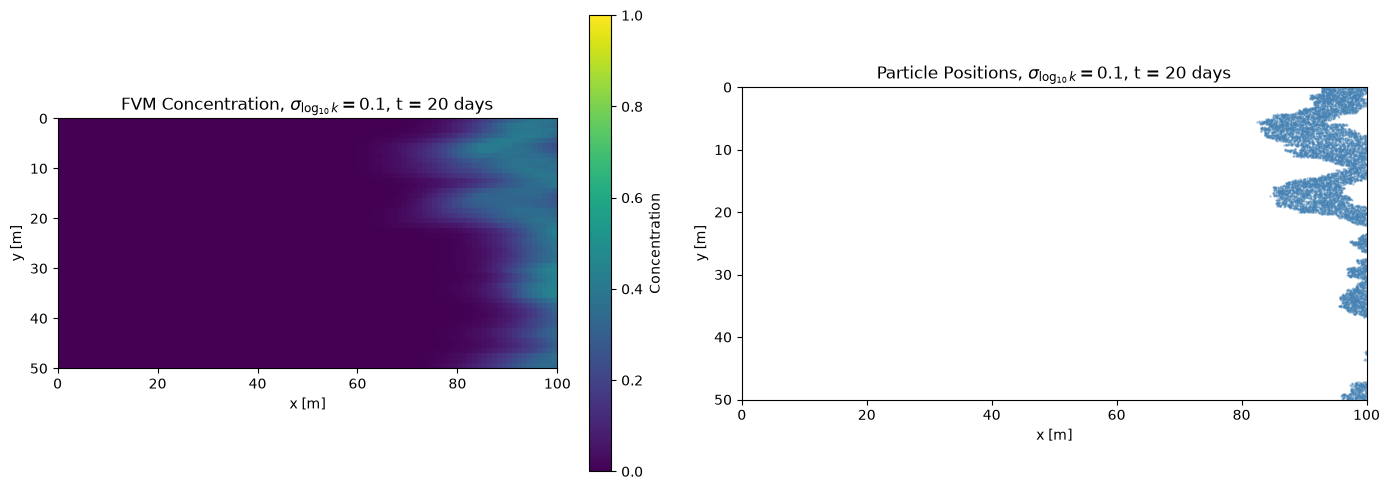

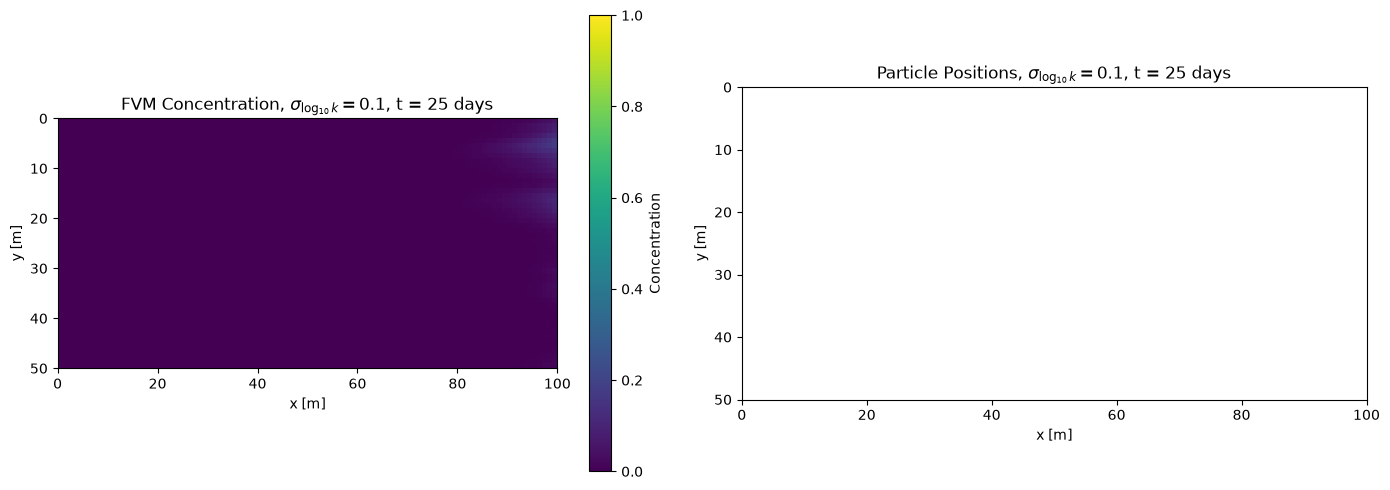

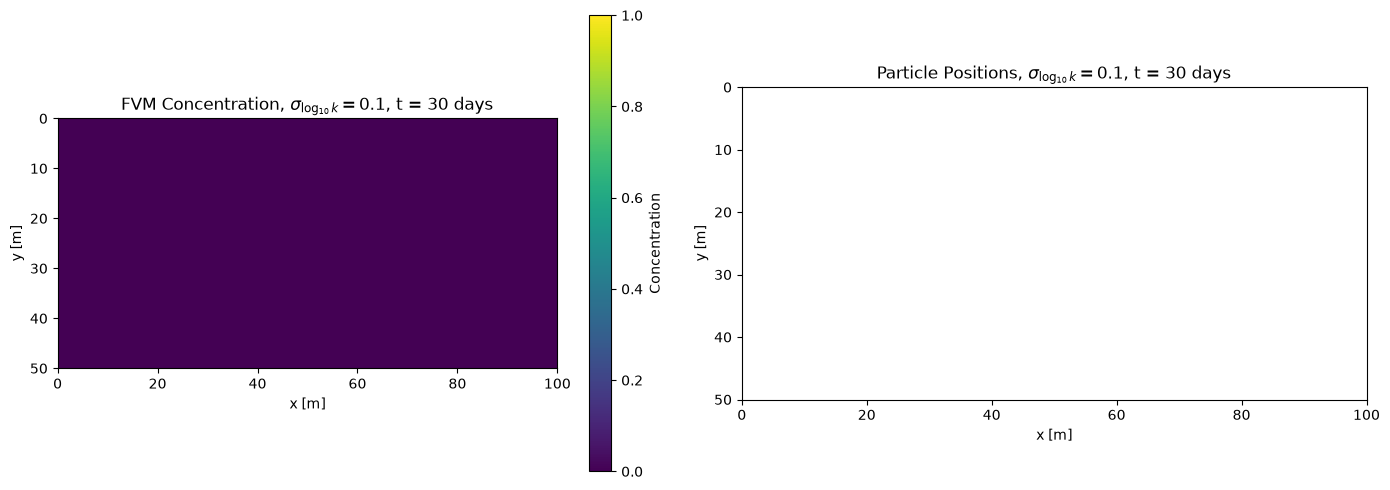

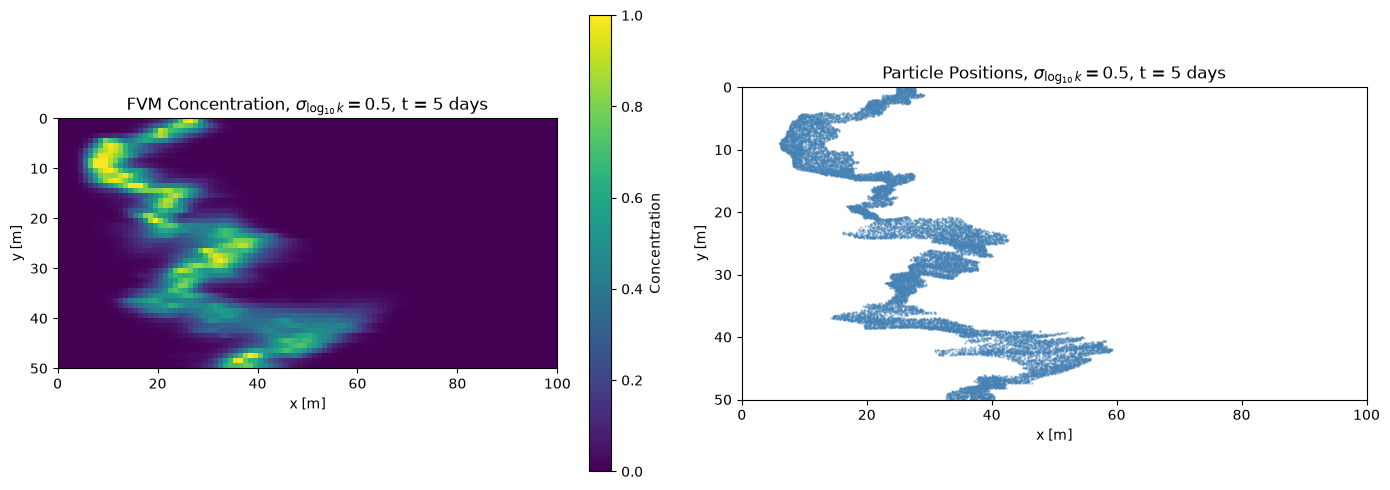

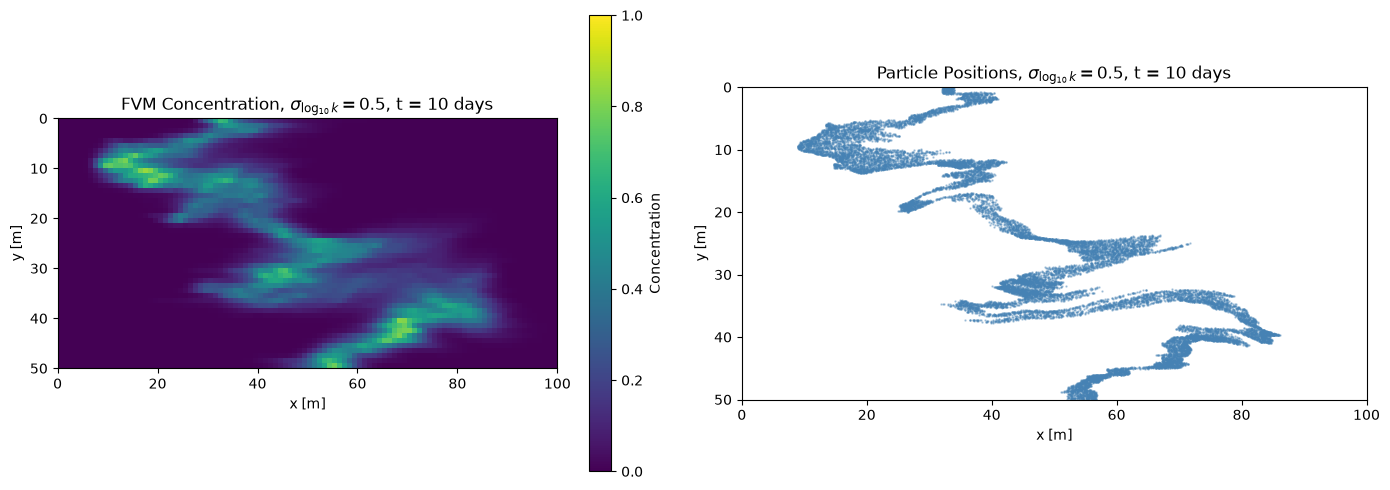

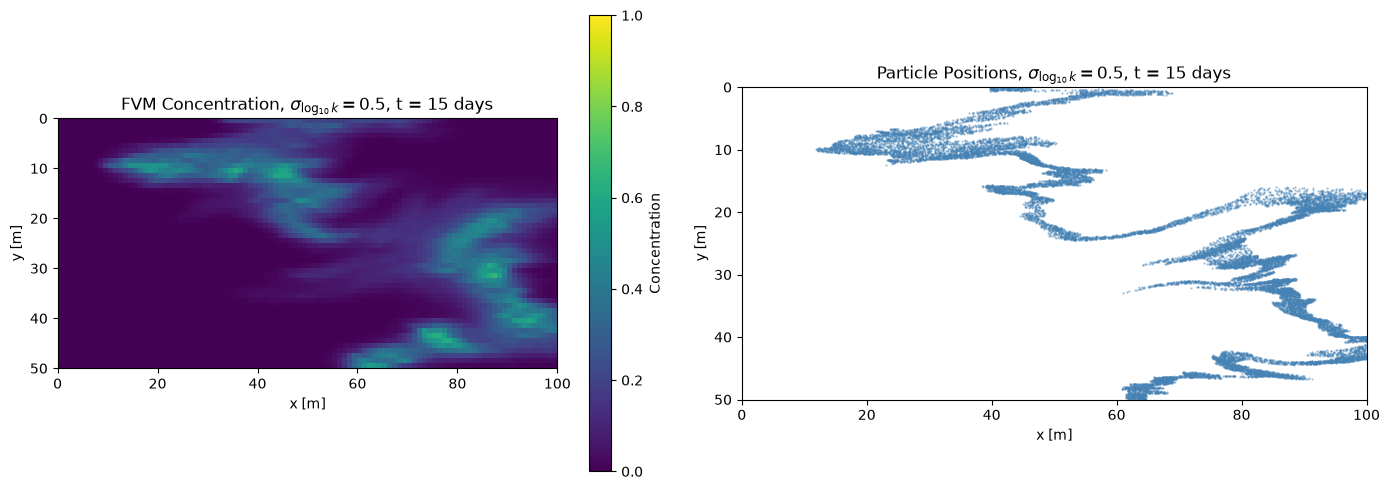

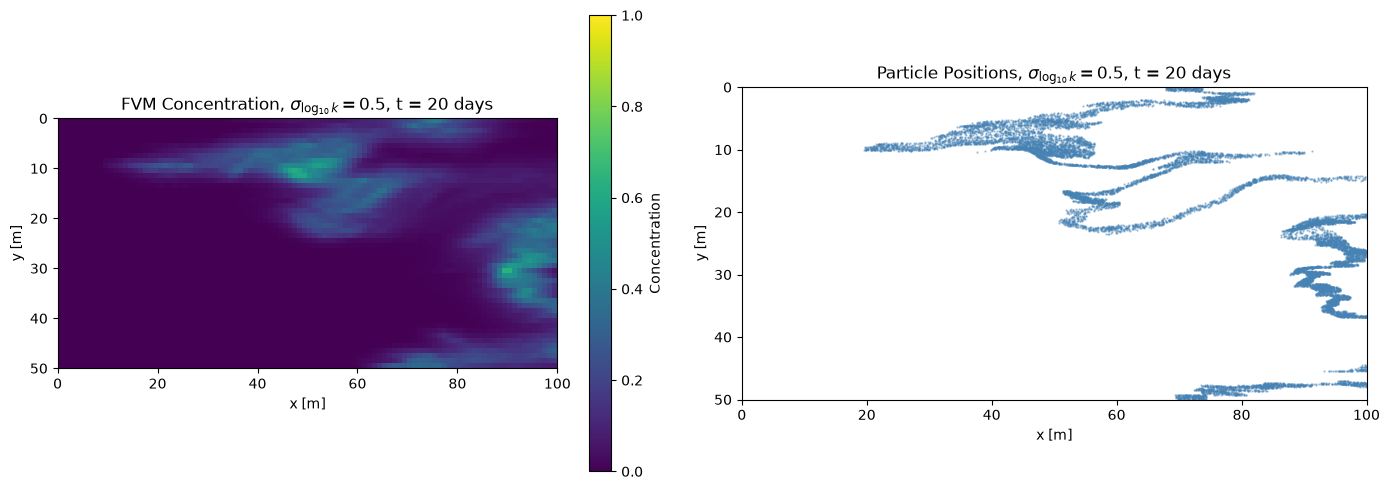

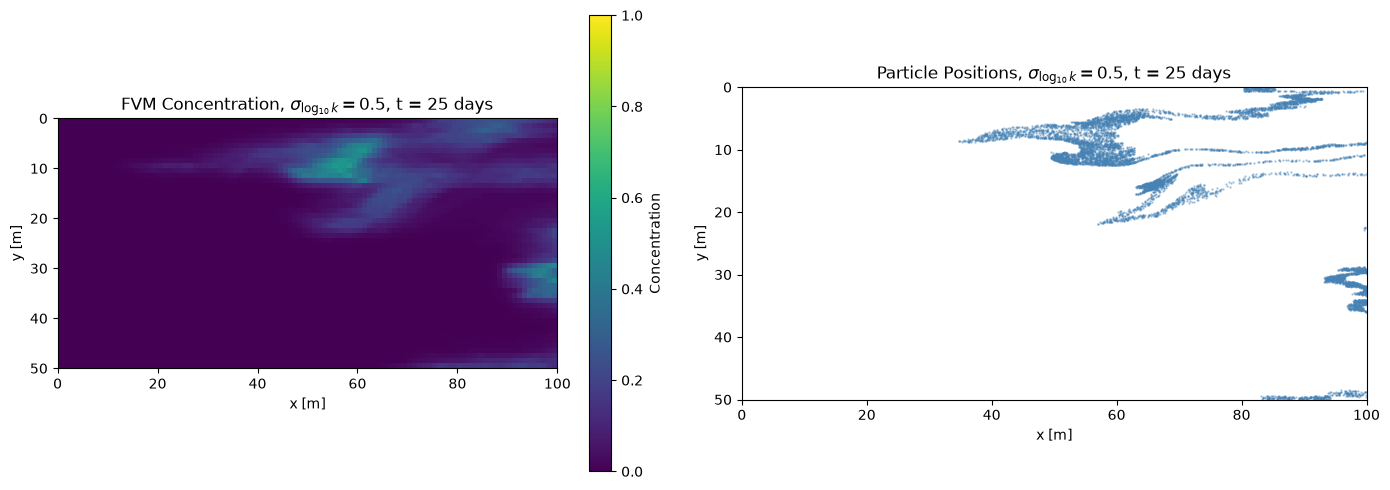

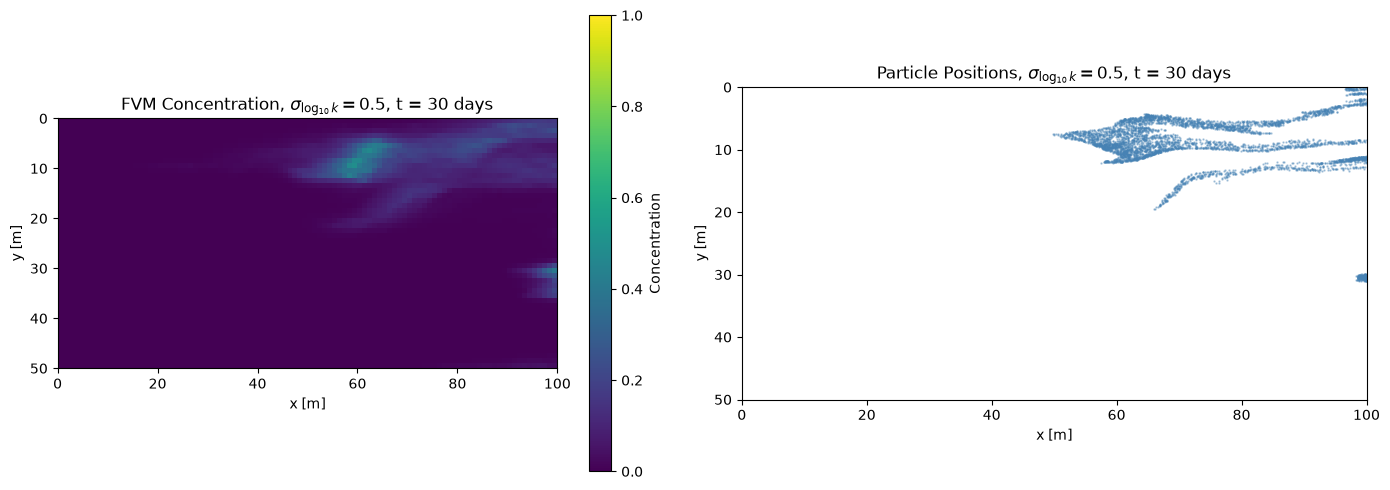

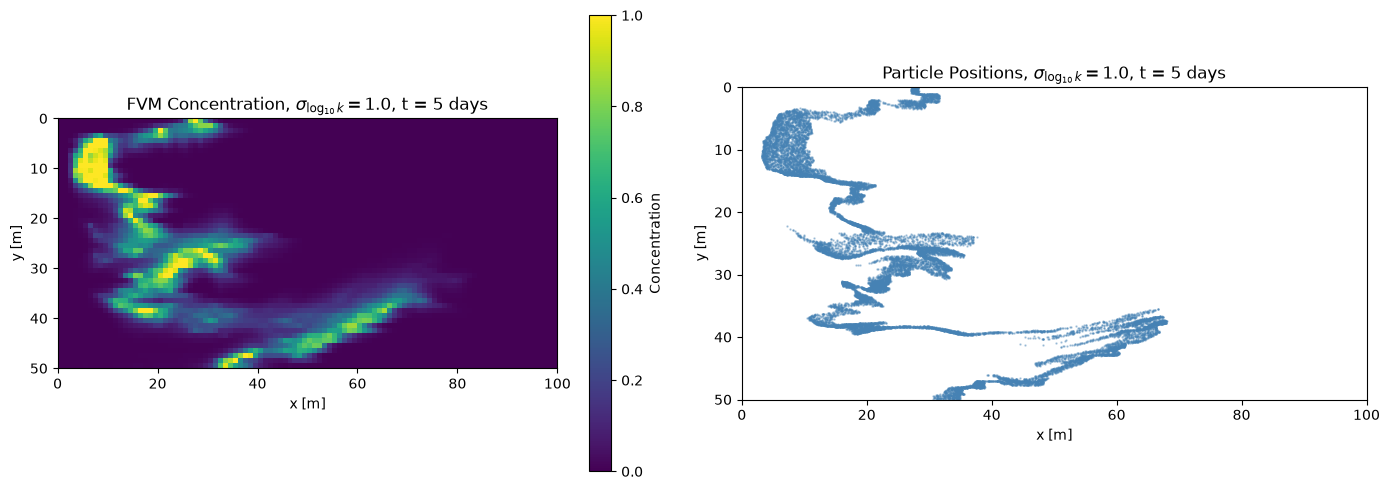

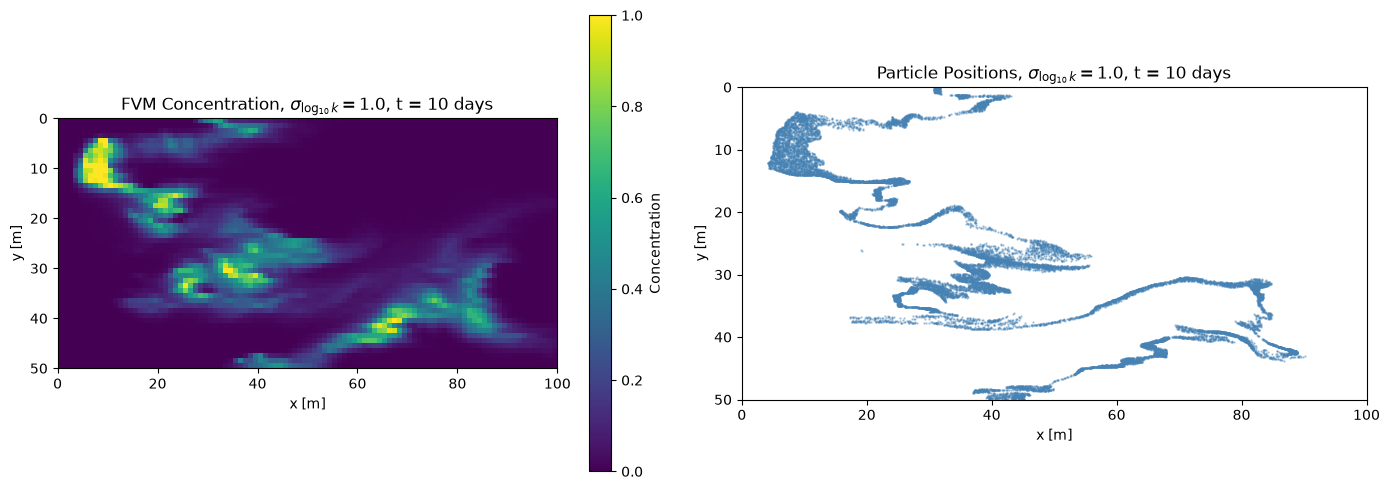

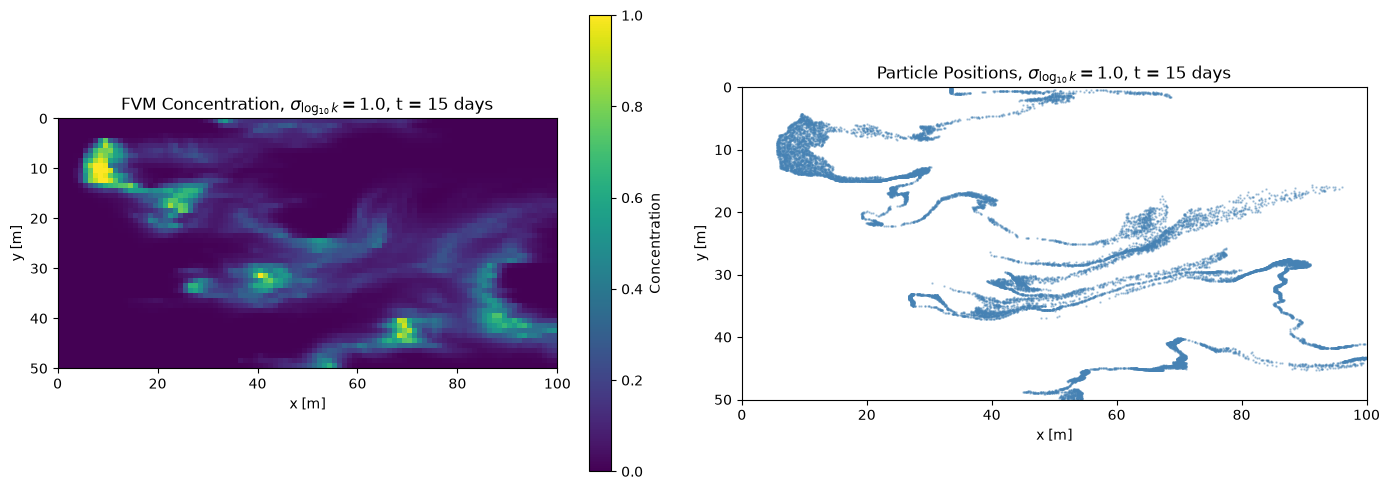

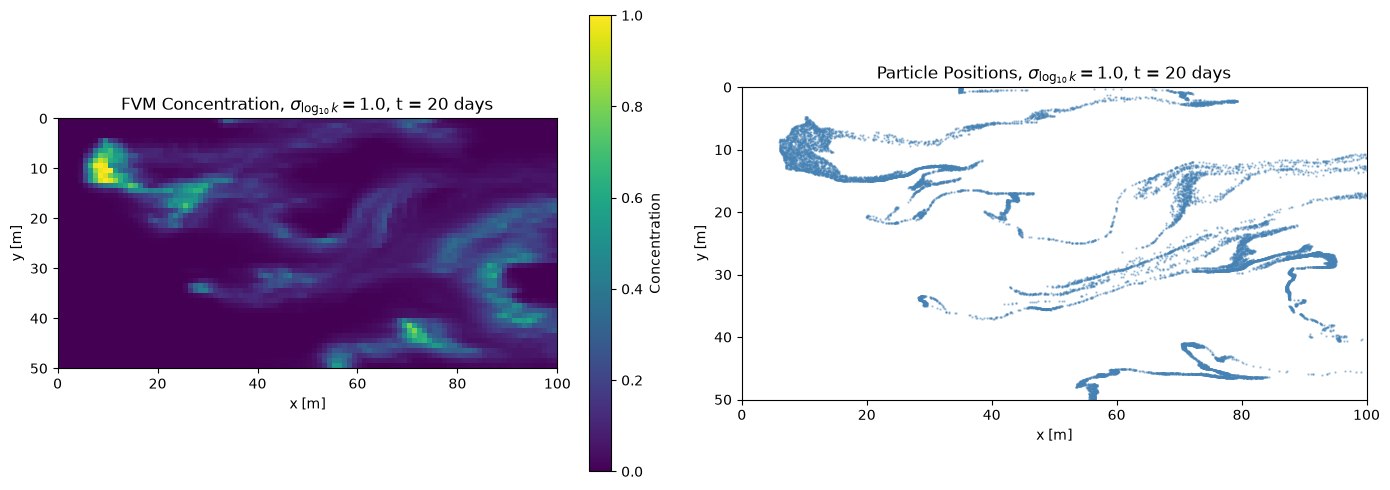

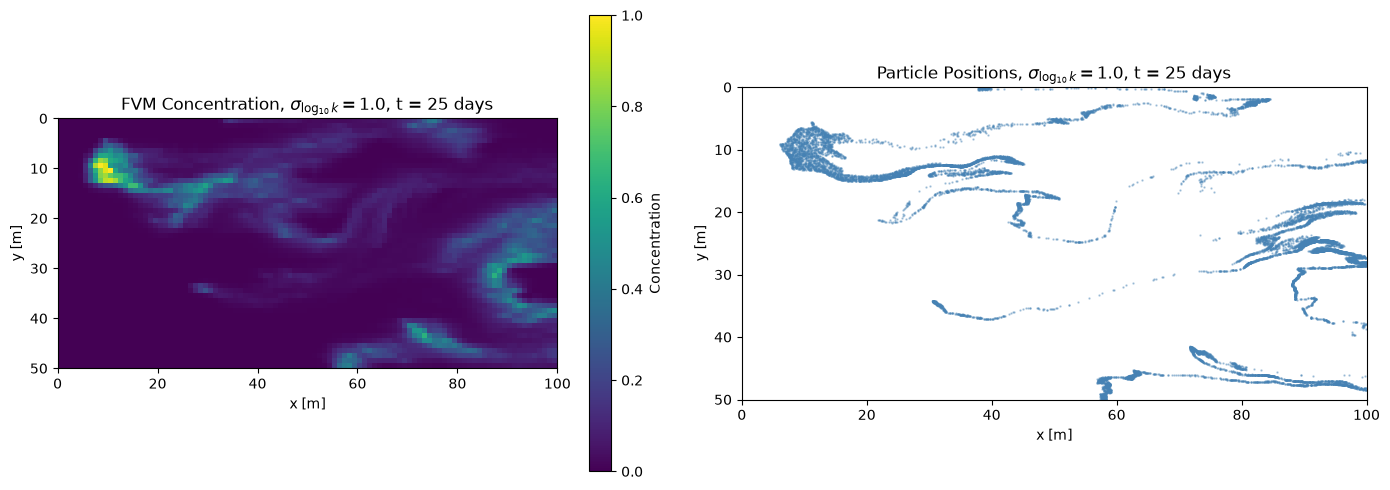

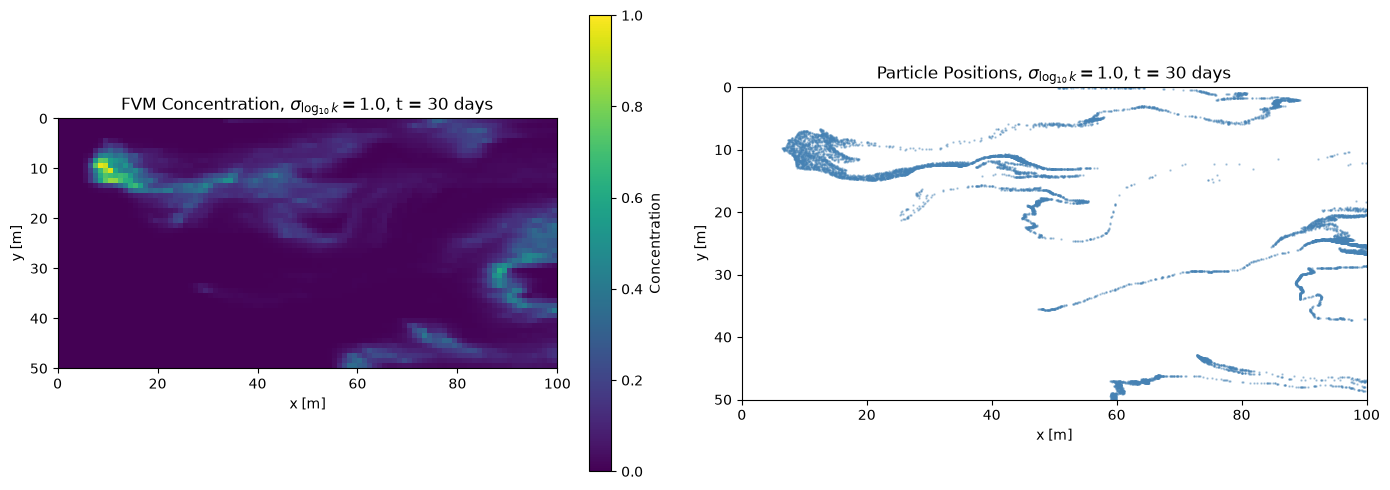

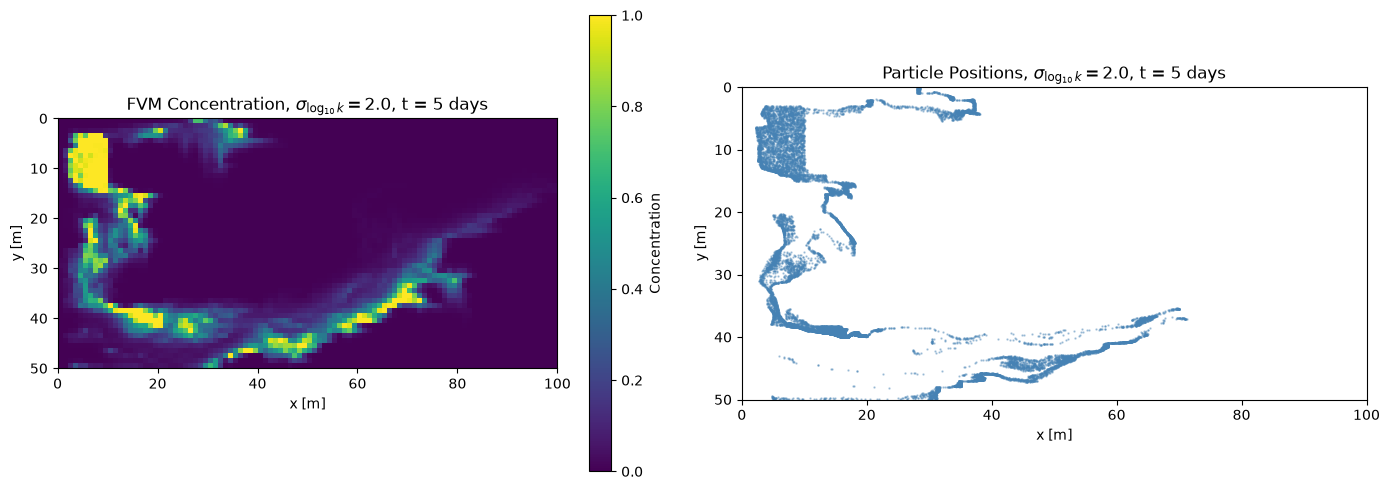

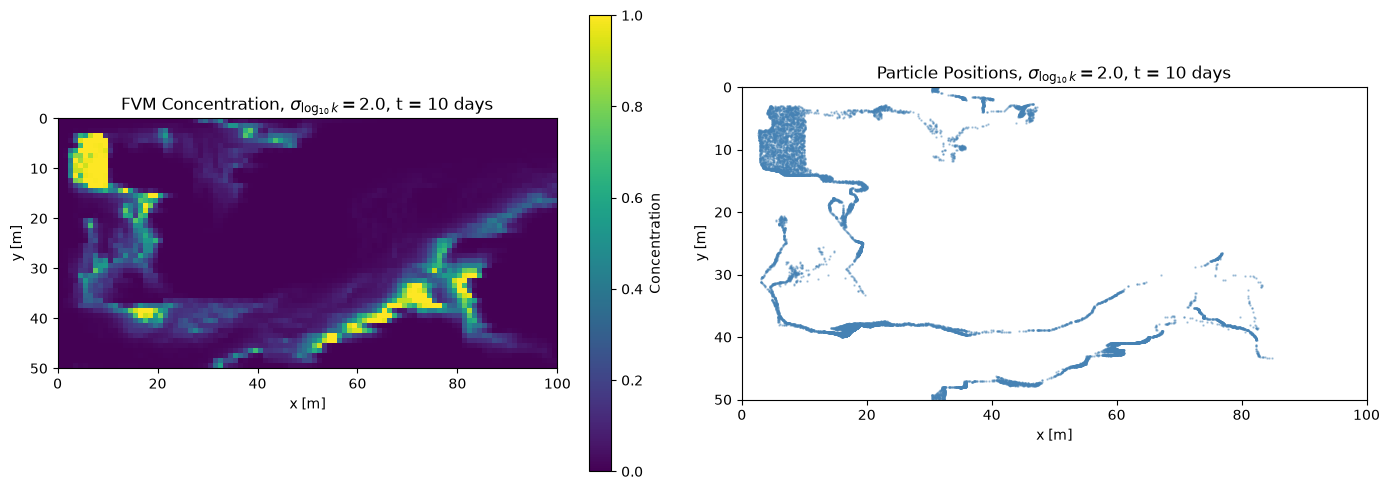

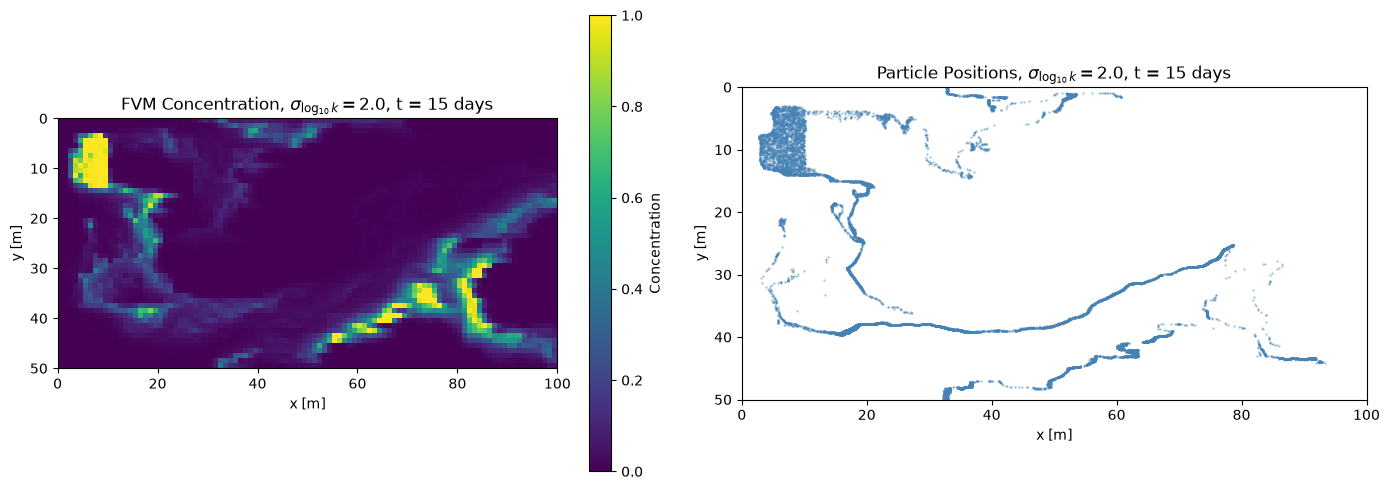

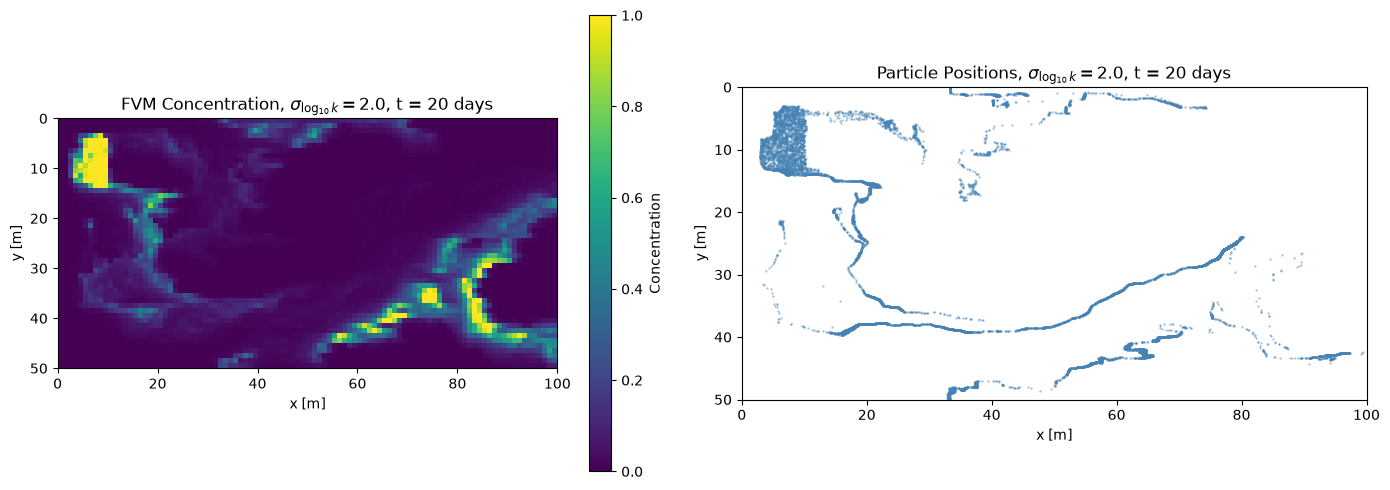

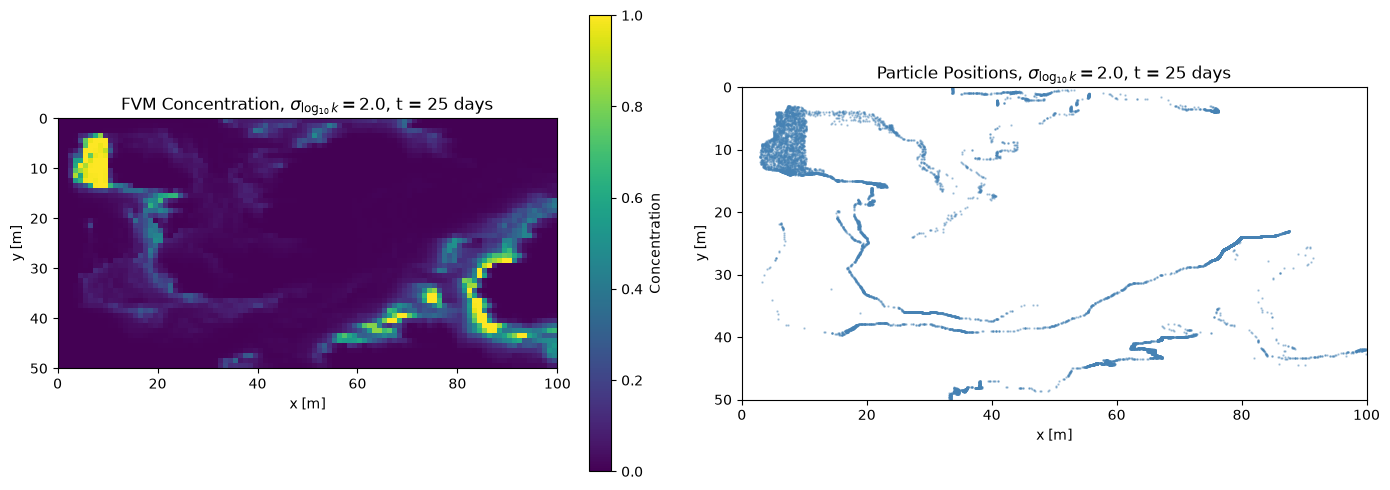

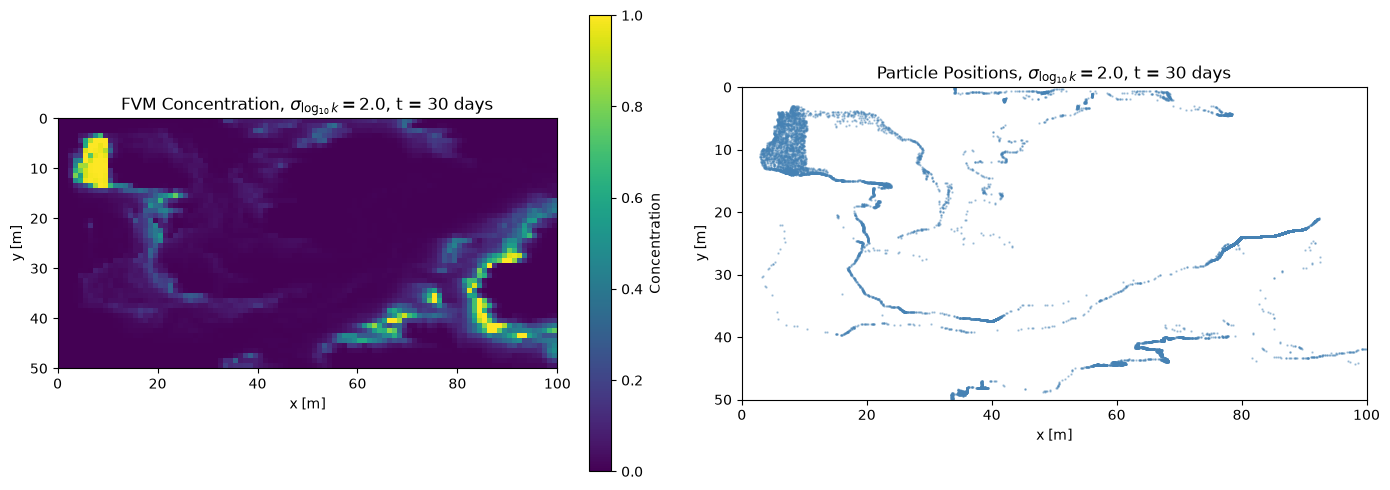

In [130]:
# 2-D concentration + particle scatter at t = 5,10,15,20,25,30 days
for sigma in sigmas:

    tFixed_days = np.arange(1, 201)   # 1…200 days

    for day in tPlot_days:
        day_f = float(day)

        if day_f not in fvm_results[sigma]:
            continue

        Cmat_plot = fvm_results[sigma][day_f]

        it = int(day) - 1   
        xp_snap = pt_xFixed[sigma][:, it]
        yp_snap = pt_yFixed[sigma][:, it]
        valid   = np.isfinite(xp_snap)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        im = axes[0].imshow(
            Cmat_plot,
            origin='upper',
            aspect='equal',
            extent=[0, Lx, Ly, 0],
            vmin=0,
            vmax=1
        )
        plt.colorbar(im, ax=axes[0], label='Concentration')
        axes[0].set_xlabel('x [m]')
        axes[0].set_ylabel('y [m]')
        axes[0].set_title(
            rf'FVM Concentration, '
            rf'$\sigma_{{\log_{{10}}k}}={sigma}$, '
            rf't = {day_f:.0f} days'
        )

        axes[1].scatter(
            xp_snap[valid],
            yp_snap[valid],
            s=0.5,
            alpha=0.4,
            color='steelblue'
        )
        axes[1].set_xlim(0, Lx)
        axes[1].set_ylim(Ly, 0)
        axes[1].set_aspect('equal')
        axes[1].set_xlabel('x [m]')
        axes[1].set_ylabel('y [m]')
        axes[1].set_title(
            rf'Particle Positions, '
            rf'$\sigma_{{\log_{{10}}k}}={sigma}$, '
            rf't = {day_f:.0f} days'
        )

        plt.tight_layout()
        plt.show()

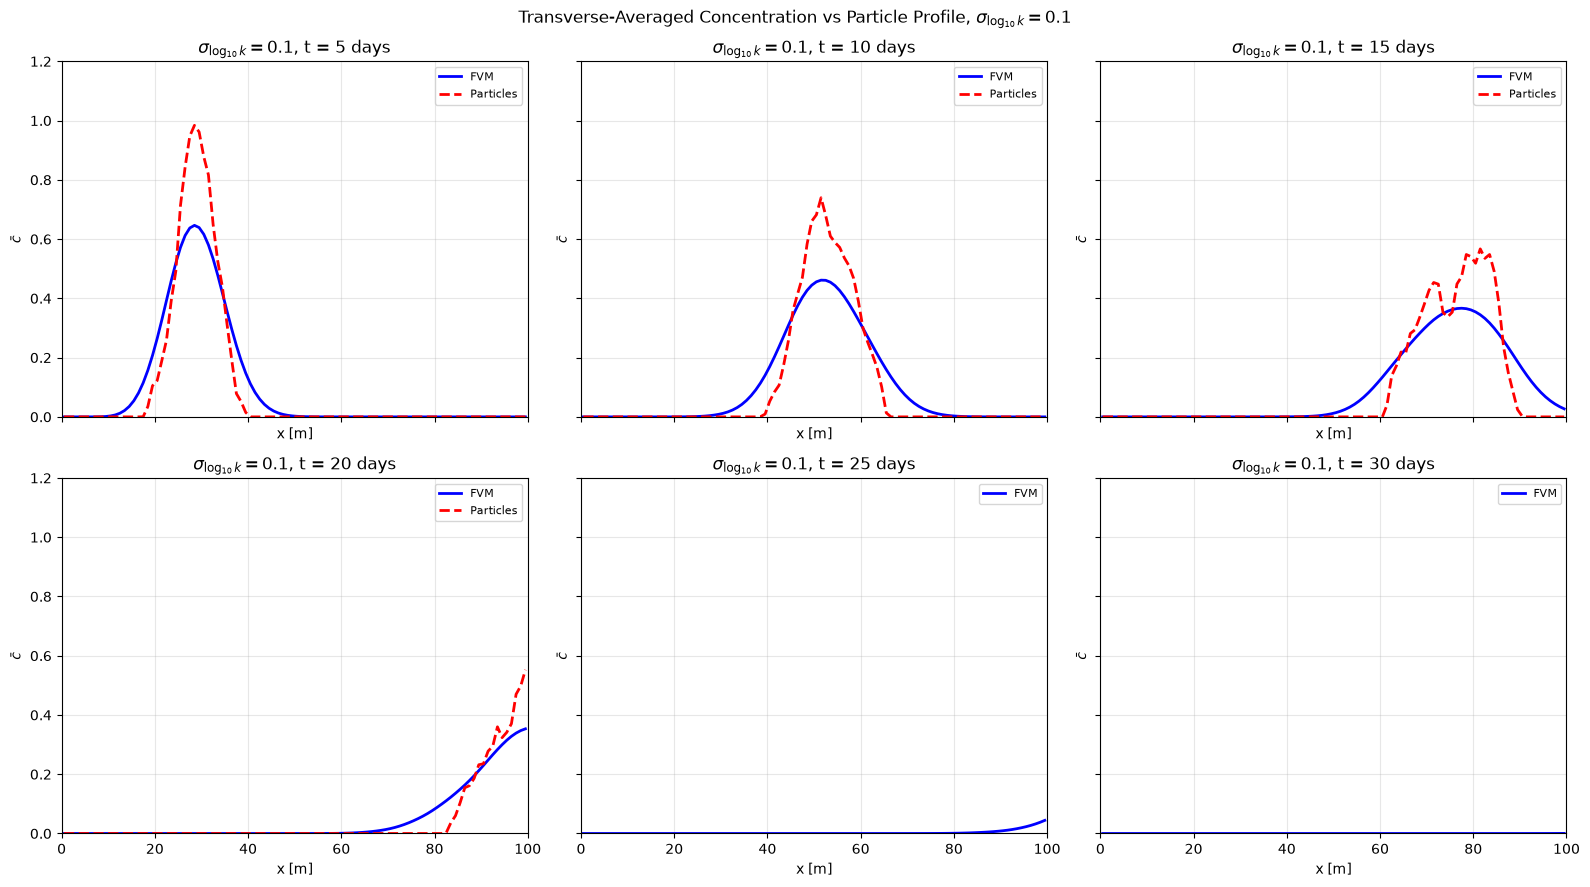

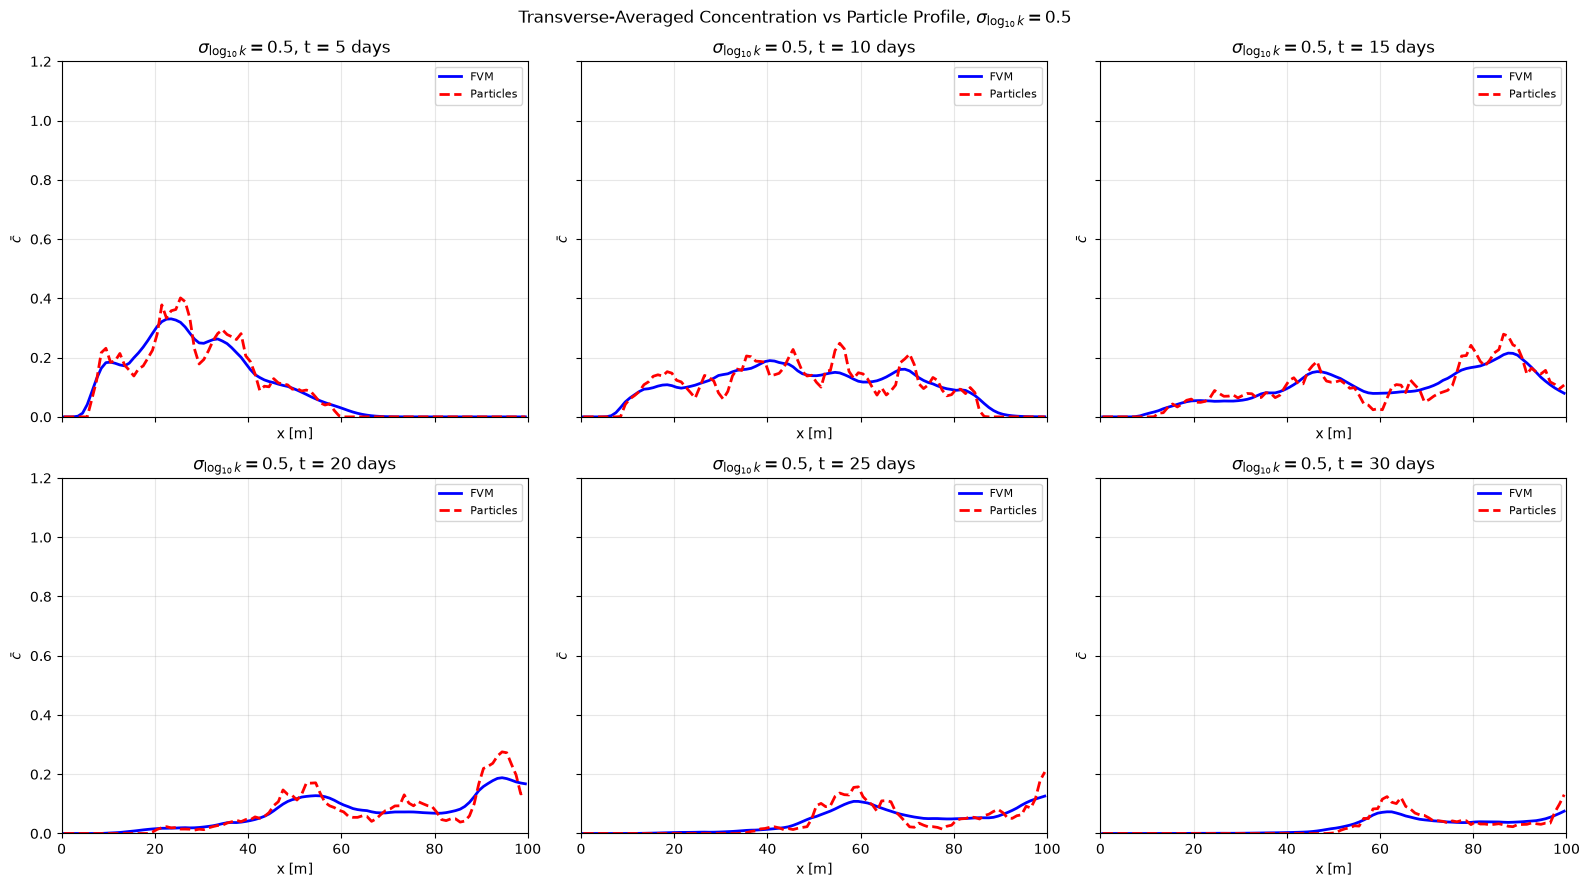

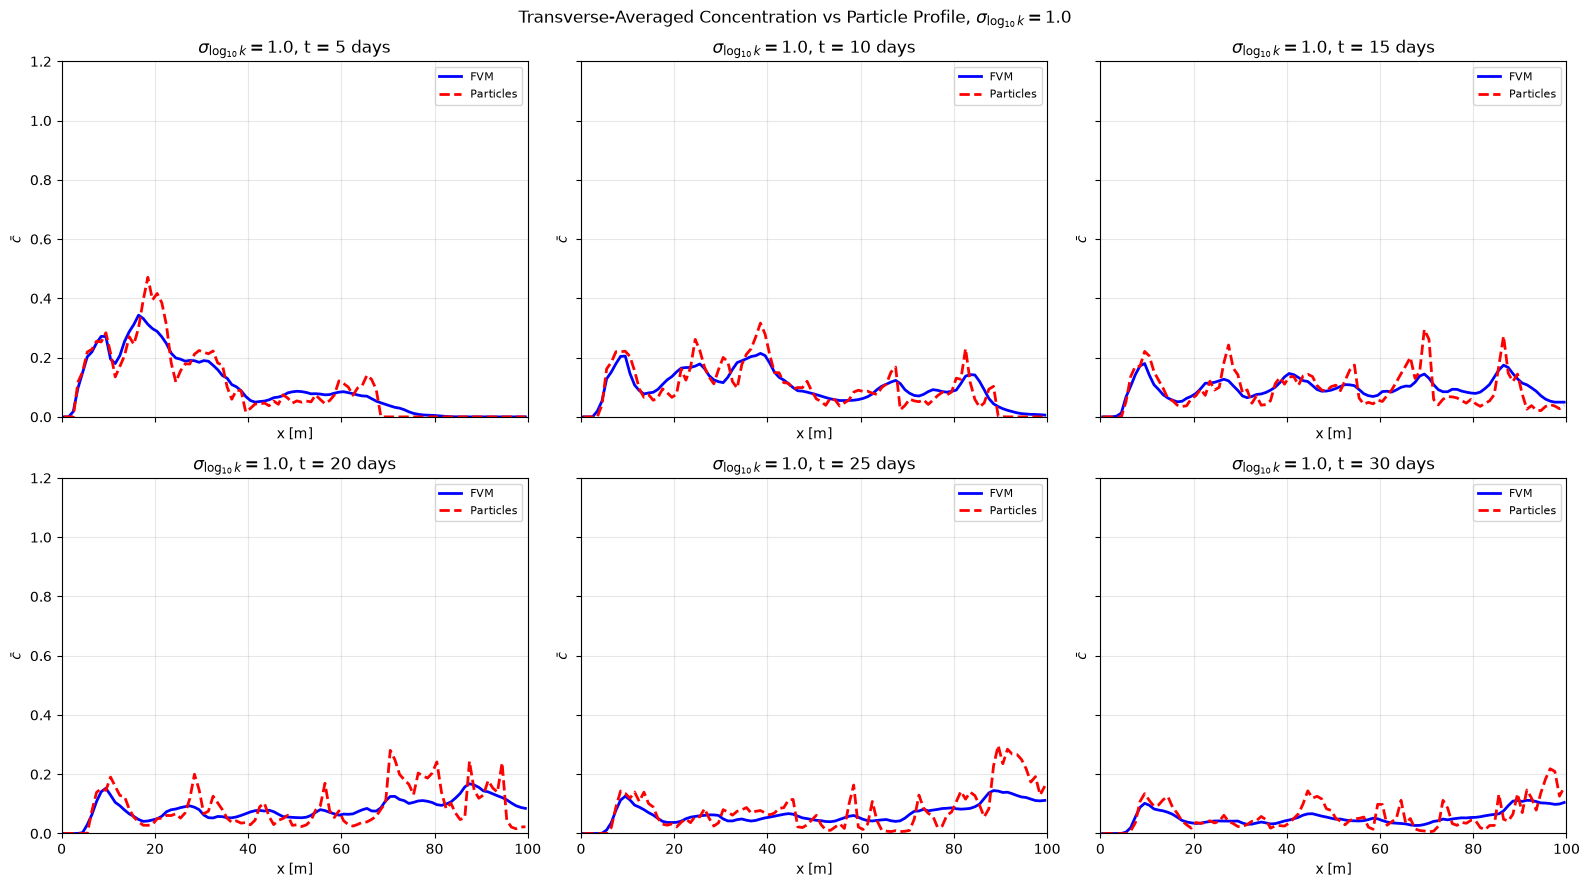

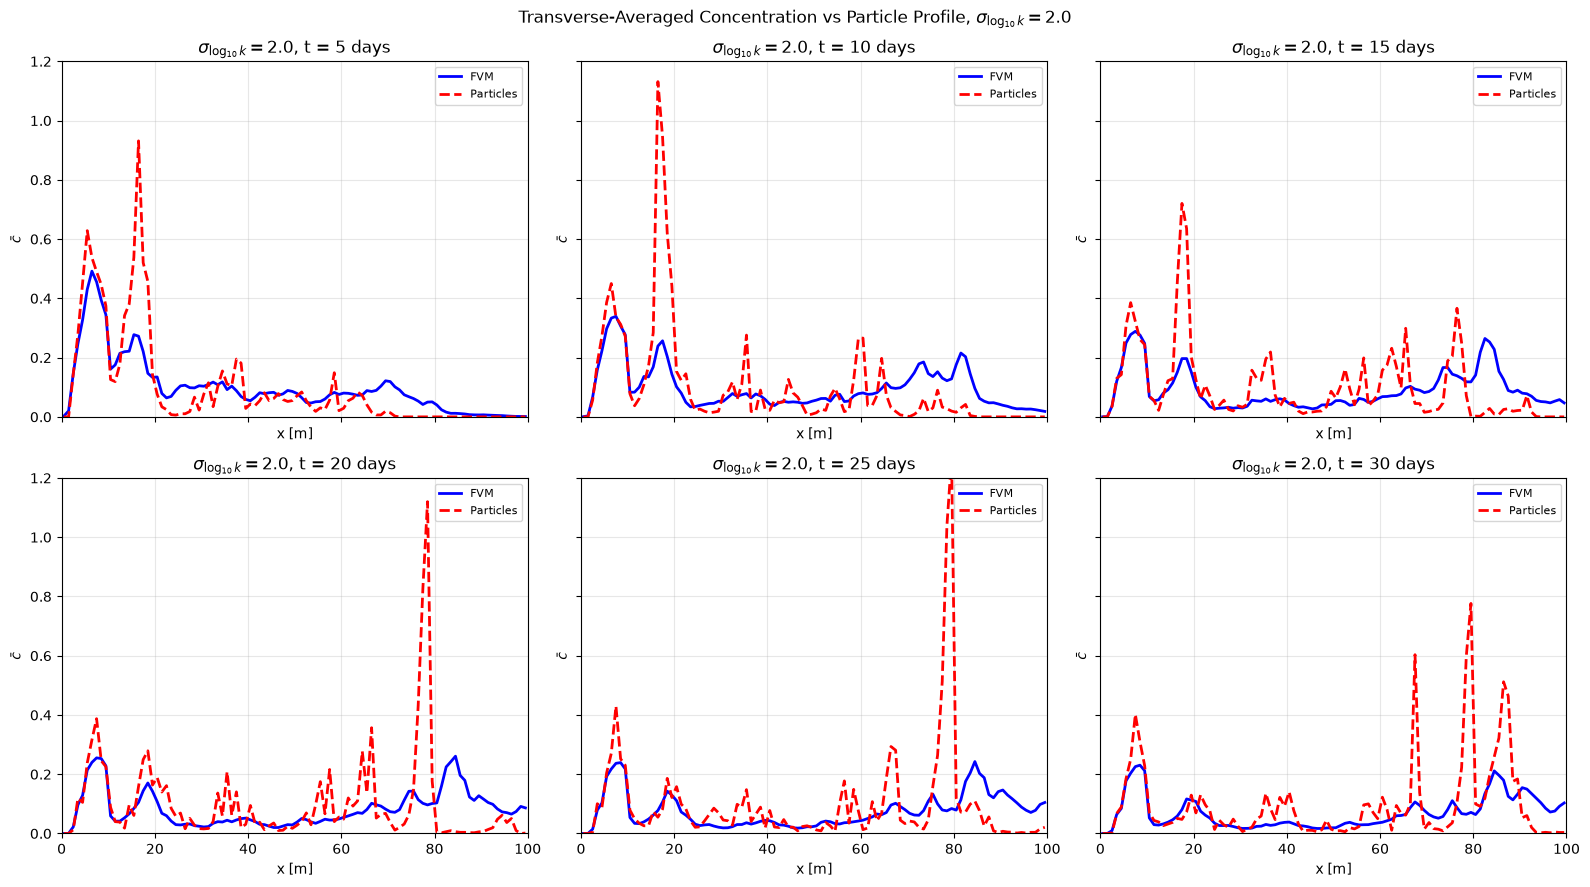

In [131]:
# Transverse-averaged concentration vs normalised particle histogram
x_edges = np.arange(0, Lx + dx, dx)

for sigma in sigmas:

    fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
    axes = axes.ravel()

    for i_day, day in enumerate(tPlot_days):
        day_f = float(day)
        ax    = axes[i_day]

        # FVM transverse average
        if day_f in fvm_results[sigma]:
            C_trans = np.mean(fvm_results[sigma][day_f], axis=0)
            ax.plot(xCells, C_trans, 'b-', linewidth=2, label='FVM')

        # Particle histogram normalised by 2000
        it = int(day) - 1
        xp_snap = pt_xFixed[sigma][:, it]
        valid   = np.isfinite(xp_snap)
        if np.any(valid):
            counts, _ = np.histogram(xp_snap[valid], bins=x_edges)
            ax.plot(
                xCells,
                counts / norm_count,
                'r--',
                linewidth=2,
                label='Particles'
            )

        ax.set_xlim(0, Lx)
        ax.set_ylim(0, 1.2)
        ax.set_xlabel('x [m]')
        ax.set_ylabel(r'$\bar{c}$')
        ax.set_title(
            rf'$\sigma_{{\log_{{10}}k}}={sigma}$, '
            rf't = {day_f:.0f} days'
        )
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    plt.suptitle(
        rf'Transverse-Averaged Concentration vs Particle Profile, '
        rf'$\sigma_{{\log_{{10}}k}}={sigma}$',
        fontsize=12
    )
    plt.tight_layout()
    plt.show()

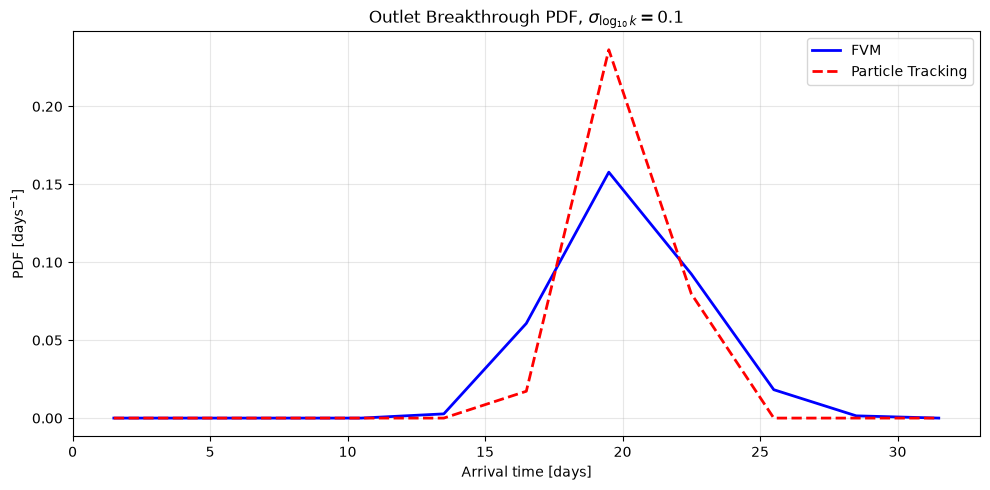

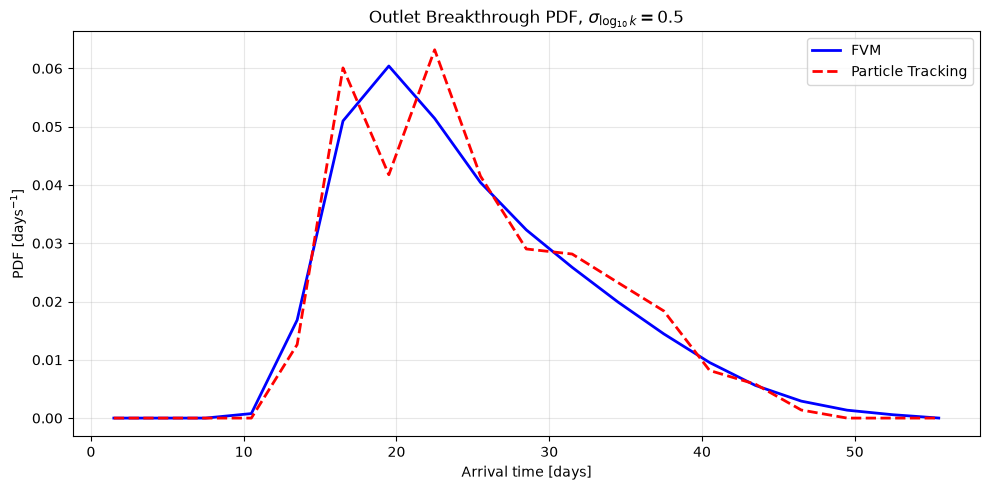

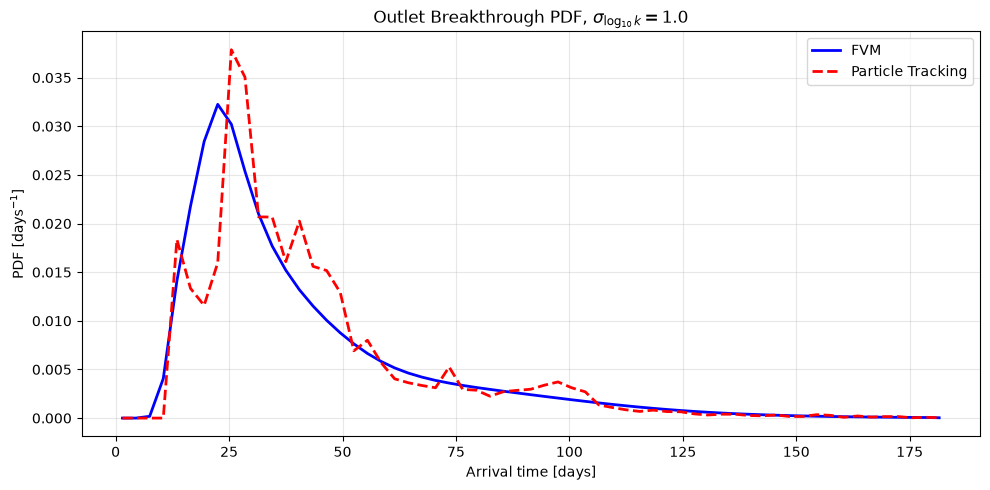

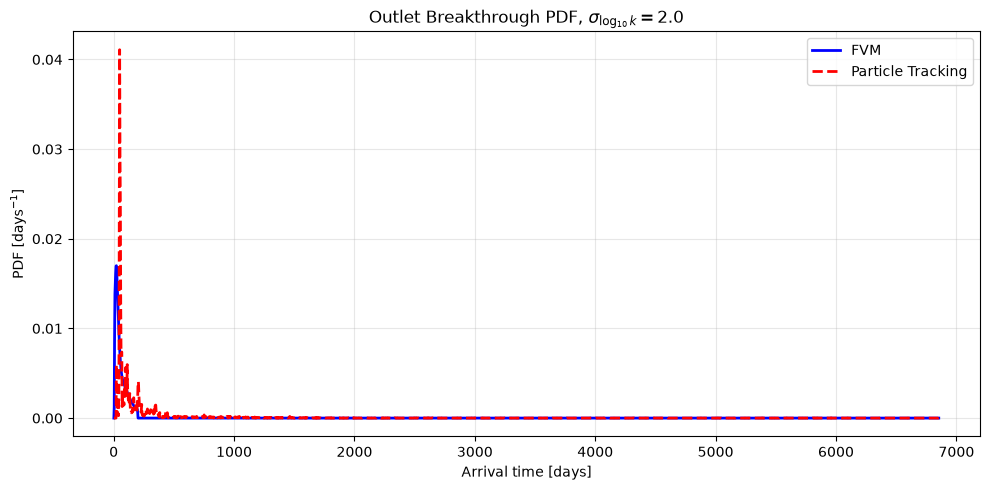

In [132]:
# outlet breakthrough PDFs
dtBin_days = 3.0
dtBin_s    = dtBin_days * 24 * 3600

for sigma in sigmas:

    fvm_t, fvm_f   = outlet_flux_fvm[sigma]
    arr_times_s    = pt_arrivalTime[sigma]
    arr_times_s    = arr_times_s[np.isfinite(arr_times_s)]

    t_max_s    = max(fvm_t[-1], arr_times_s.max() if len(arr_times_s) else fvm_t[-1])
    t_max_days = t_max_s / (24 * 3600)

    bin_edges_days = np.arange(0, t_max_days + dtBin_days, dtBin_days)
    bin_edges_s    = bin_edges_days * 24 * 3600
    bin_centers    = 0.5 * (bin_edges_days[:-1] + bin_edges_days[1:])

    # FVM PDF (integrate flux into bins)
    fvm_pdf = np.zeros(len(bin_centers))
    for ib in range(len(bin_centers)):
        t_lo = bin_edges_s[ib]
        t_hi = bin_edges_s[ib + 1]
        mask = (fvm_t >= t_lo) & (fvm_t < t_hi)
        if np.any(mask):
            fvm_pdf[ib] = np.trapezoid(fvm_f[mask], fvm_t[mask])

    total_fvm = np.sum(fvm_pdf)
    if total_fvm > 0:
        fvm_pdf = fvm_pdf / (total_fvm * dtBin_days)

    # Particle-tracking PDF (histogram of arrival times)
    arr_days     = arr_times_s / (24 * 3600)
    pt_counts, _ = np.histogram(arr_days, bins=bin_edges_days)
    total_pt     = np.sum(pt_counts)
    pt_pdf       = pt_counts / (total_pt * dtBin_days) if total_pt > 0 else np.zeros_like(pt_counts, dtype=float)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(bin_centers, fvm_pdf, 'b-',  linewidth=2, label='FVM')
    ax.plot(bin_centers, pt_pdf,  'r--', linewidth=2, label='Particle Tracking')

    ax.set_xlabel('Arrival time [days]')
    ax.set_ylabel(r'PDF [days$^{-1}$]')
    ax.set_title(
        rf'Outlet Breakthrough PDF, '
        rf'$\sigma_{{\log_{{10}}k}}={sigma}$'
    )
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()